In [1]:
"""
This experiment evaluates DriftWatch detectors on real telemetry data.

Unlike the synthetic bakeoff, no complete ground truth labels are available.
Therefore, this notebook focuses on detector behavior, alert frequency, and
whether alerts align with meaningful system changes.s
"""

'\nThis experiment evaluates DriftWatch detectors on real telemetry data.\n\nUnlike the synthetic bakeoff, no complete ground truth labels are available.\nTherefore, this notebook focuses on detector behavior, alert frequency, and\nwhether alerts align with meaningful system changes.s\n'

In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DB_PATH
from src.detectors import (
    run_zscore_detector,
    run_mahalanobis_detector,
    run_cusum_detector,
    run_ocsvm_detector,
)


In [3]:
db_path = DB_PATH

run_zscore_detector(db_path)
run_mahalanobis_detector(db_path)
run_cusum_detector(db_path)
run_ocsvm_detector(db_path)


zscore run 94: 632/1944 rows flagged (32.5%)
fitting on 1888/1944 baseline rows excluding 56 known anomaly events
mahalanobis run 95: threshold=29.79, 200/1898 scored rows flagged (10.5%)
cusum run 96: 157/1944 rows flagged (8.1%)
ocsvm run 97: fit on 1887 baseline rows, scored 1943 rows, 99/1943 flagged (5.1%)


In [4]:
def load_detections(db_path):
    with sqlite3.connect(db_path) as conn:
        return pd.read_sql_query(
            """
            SELECT
                d.metrics_id,
                d.score,
                d.is_anomaly,
                r.method,
                m.timestamp,
                m.cpu_percent,
                m.ram_percent,
                m.gpu_percent,
                m.cpu_temp,
                m.gpu_temp
            FROM detections d
            JOIN detection_runs r
                ON d.run_id = r.id
            JOIN metrics m
                ON d.metrics_id = m.id
            ORDER BY m.timestamp ASC
            """,
            conn
        )

detections = load_detections(db_path)
detections["timestamp"] = pd.to_datetime(detections["timestamp"])

detections.head()


,metrics_id,score,is_anomaly,method,timestamp,cpu_percent,ram_percent,gpu_percent,cpu_temp,gpu_temp
0,7,0.000000,0,zscore,2026-09-02 19:16:20.102694+00:00,11.6,42.7,0.0,96.0,72.0
1,7,0.000000,0,cusum,2026-09-02 19:16:20.102694+00:00,11.6,42.7,0.0,96.0,72.0
2,8,0.674491,0,zscore,2026-09-02 19:16:51.759239+00:00,5.9,42.3,0.0,78.0,73.0
3,8,22.600069,0,mahalanobis,2026-09-02 19:16:51.759239+00:00,5.9,42.3,0.0,78.0,73.0
4,8,0.000000,0,cusum,2026-09-02 19:16:51.759239+00:00,5.9,42.3,0.0,78.0,73.0


In [5]:
summary = detections.groupby("method")["is_anomaly"].agg(
    alerts="sum",
    total="count"
)

summary["alert_rate_%"] = (
    summary["alerts"] / summary["total"] * 100
).round(2)

summary


,alerts,total,alert_rate_%
method,,,
cusum,157,1944,8.08
mahalanobis,200,1898,10.54
ocsvm,99,1943,5.10
zscore,632,1944,32.51


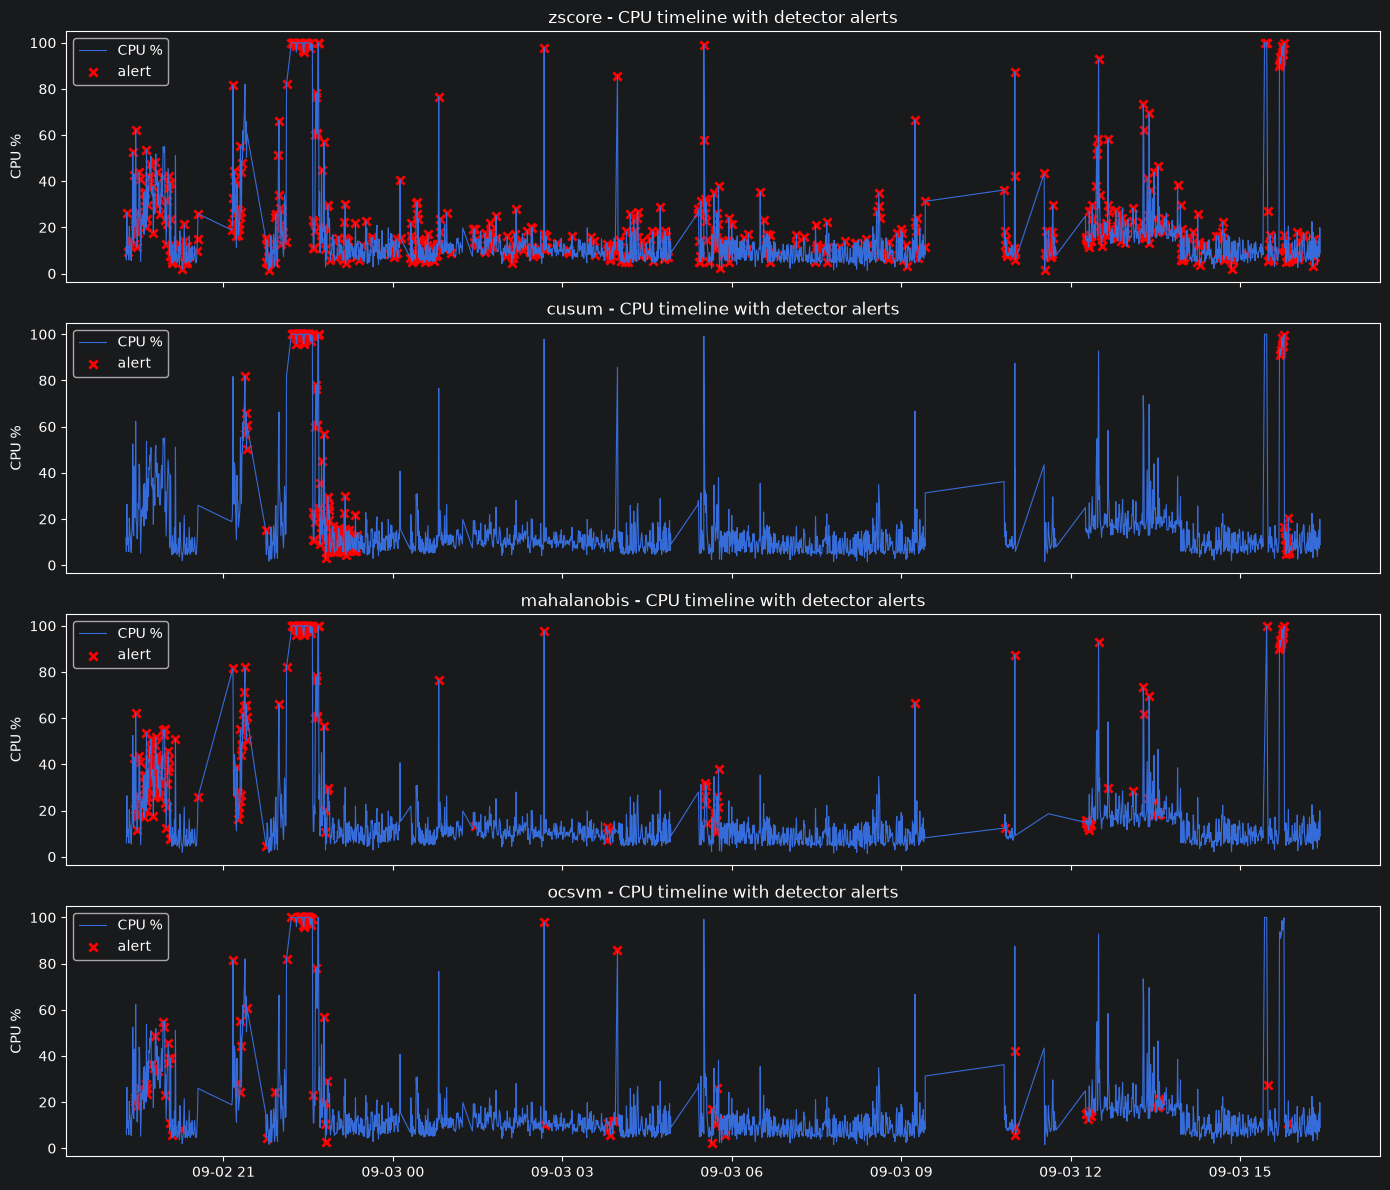

In [6]:
methods = detections["method"].unique()

plot_df = detections.sort_values("timestamp").copy()

time_diff = plot_df["timestamp"].diff()

gap_threshold = pd.Timedelta(hours=2)

plot_df["plot_time"] = plot_df["timestamp"]

offset = pd.Timedelta(0)

for i in range(1, len(plot_df)):
    if time_diff.iloc[i] > gap_threshold:
        offset += time_diff.iloc[i]

    plot_df.loc[plot_df.index[i], "plot_time"] -= offset


fig, axes = plt.subplots(
    len(methods),
    1,
    figsize=(14, 3 * len(methods)),
    sharex=True
)

if len(methods) == 1:
    axes = [axes]

for ax, method in zip(axes, methods):

    subset = plot_df[plot_df["method"] == method]

    ax.plot(
        subset["plot_time"],
        subset["cpu_percent"],
        linewidth=0.8,
        label="CPU %"
    )

    alerts = subset[subset["is_anomaly"] == 1]

    ax.scatter(
        alerts["plot_time"],
        alerts["cpu_percent"],
        s=35,
        marker="x",
        color="red",
        linewidths=2,
        label="alert"
    )

    ax.set_title(f"{method} - CPU timeline with detector alerts")
    ax.set_ylabel("CPU %")
    ax.legend()

plt.tight_layout()
plt.show()

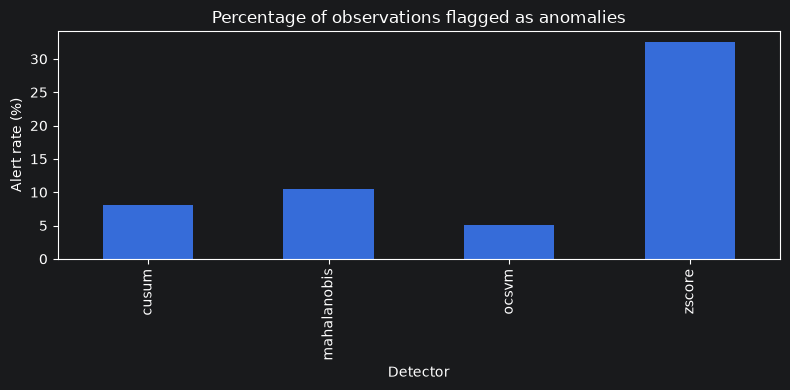

In [7]:
plt.figure(figsize=(8,4))

(detections.groupby("method")["is_anomaly"].mean() * 100).plot.bar()

plt.ylabel("Alert rate (%)")
plt.xlabel("Detector")
plt.title("Percentage of observations flagged as anomalies")

plt.tight_layout()
plt.show()